## 1. Import import

In [244]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

## 2. Load dataset

In [245]:
from pathlib import Path

file_path = Path("train.csv")

if file_path.exists():
    df = pd.read_csv(file_path)

print("Ukuran dataset:", df.shape)

Ukuran dataset: (891, 12)


In [246]:
# Melihat lima baris pertama
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [247]:
# Melihat lima baris terakhir
df.tail()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.00,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.00,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q


In [248]:
# Melihat nama kolom dan tipe datanya
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


Diketahui bahwa banyak baris Cabin yang berisi NaN dan juga ratusan baris Age berisi NaN serta 2 baris Embarked terisi NaN

In [249]:
# Statistik deskriptif untuk kolom numerik
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [250]:
# Statistik deskriptif untuk kolom kategorikal
df.describe(include="object")

C:\Users\NathanLampoenk2\AppData\Local\Temp\ipykernel_16200\3220601123.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object")


,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Braund, Mr. Owen Harris",male,347082,G6,S
freq,1,577,7,4,644


## 3. Exploratory Data Analysis (EDA)

### 3.1 Memahami target

In [251]:
# Jumlah penumpang yang selamat dan tidak selamat
df["Survived"].value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

Lebih banyak penumpang yang tidak selamat

In [252]:
# Proporsi penumpang yang selamat dan tidak selamat
survival_rate = df["Survived"].value_counts(normalize=True) * 100
survival_rate

Survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64

Persentase keselamatan berada di 38.4%

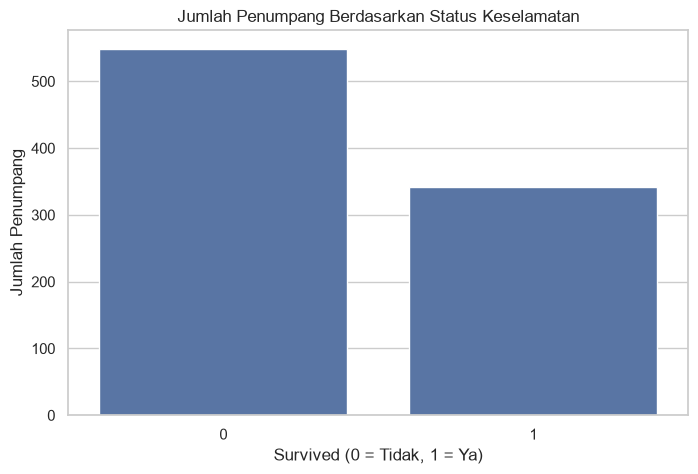

In [253]:
# Visualisasi distribusi target
sns.countplot(data=df, x="Survived")
plt.title("Jumlah Penumpang Berdasarkan Status Keselamatan")
plt.xlabel("Survived (0 = Tidak, 1 = Ya)")
plt.ylabel("Jumlah Penumpang")
plt.show()

Dari gambar dapat disimpulkan bahwa target cukup didominasi oleh 0 atau tidak selamat

### 3.2 Distribusi usia

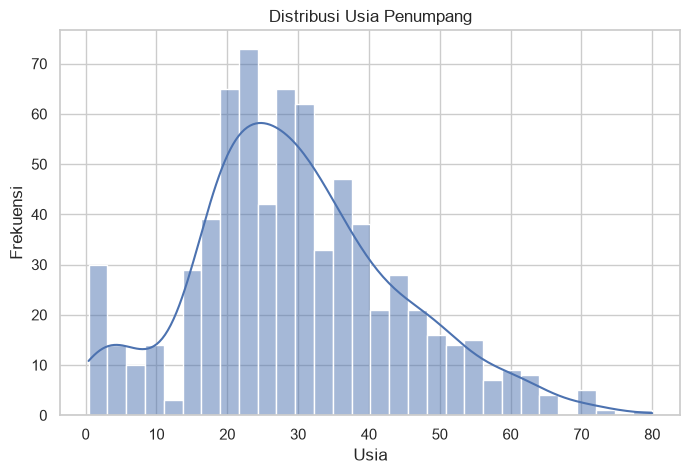

In [254]:
# Distribusi usia penumpang
sns.histplot(data=df, x="Age", bins=30, kde=True)
plt.title("Distribusi Usia Penumpang")
plt.xlabel("Usia")
plt.ylabel("Frekuensi")
plt.show()

In [255]:
# Ringkasan usia
df["Age"].describe()

count    714.000000
mean      29.699118
std       14.526497
min        0.420000
25%       20.125000
50%       28.000000
75%       38.000000
max       80.000000
Name: Age, dtype: float64

Usia penumpang paling banyak berada disekitar umur 23an dengan usia rata rata 30 tahun, tidak ada penumpang di umur 68-69

### 3.3 Keselamatan berdasarkan jenis kelamin

In [256]:
# Tingkat keselamatan berdasarkan jenis kelamin
survival_by_sex = df.groupby("Sex")["Survived"].mean()
survival_by_sex

Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64

Lebih banyak penumpang wanita yang selamat

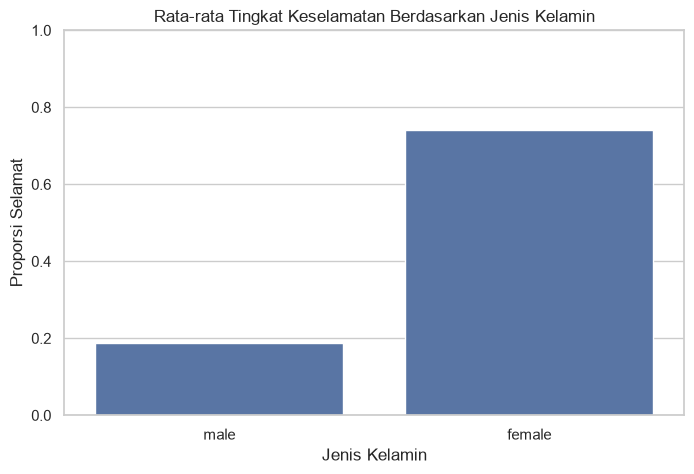

In [257]:
sns.barplot(data=df, x="Sex", y="Survived", errorbar=None)
plt.title("Rata-rata Tingkat Keselamatan Berdasarkan Jenis Kelamin")
plt.xlabel("Jenis Kelamin")
plt.ylabel("Proporsi Selamat")
plt.ylim(0, 1)
plt.show()

Penumpang wanita memiliki tingkat keselamatan yang lebih tinggi, kemungkinan besar jenis kelamin akan berpengaruh pada keselamatan

### 3.4 Keselamatan berdasarkan kelas tiket

In [258]:
# Tingkat keselamatan untuk setiap kelas penumpang
df.groupby("Pclass")["Survived"].agg(["mean", "count"])

,mean,count
Pclass,,
1,0.629630,216
2,0.472826,184
3,0.242363,491


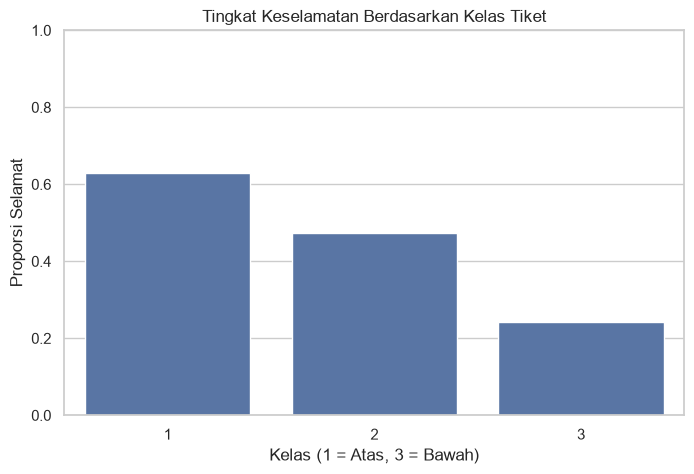

In [259]:
sns.barplot(data=df, x="Pclass", y="Survived", errorbar=None)
plt.title("Tingkat Keselamatan Berdasarkan Kelas Tiket")
plt.xlabel("Kelas (1 = Atas, 3 = Bawah)")
plt.ylabel("Proporsi Selamat")
plt.ylim(0, 1)
plt.show()

Kelas 1 dengan tingkat keselamatan tertinggi disusul oleh kelas 2 dan 3, kelas juga mungkin berpengaruh pada tingkat keselamatan

### 3.5 Distribusi tarif tiket

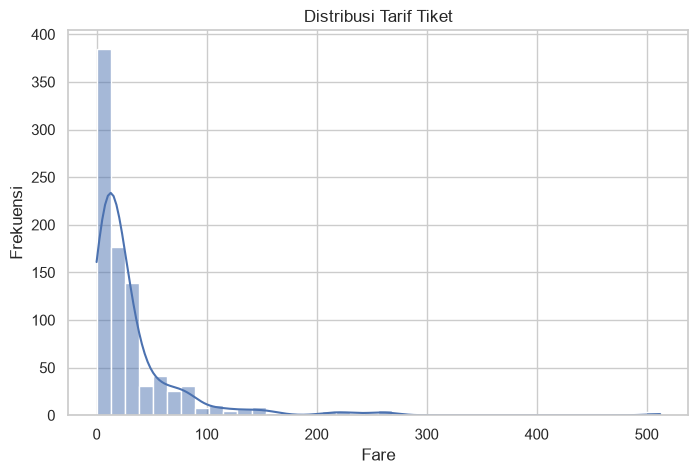

In [260]:
sns.histplot(data=df, x="Fare", bins=40, kde=True)
plt.title("Distribusi Tarif Tiket")
plt.xlabel("Fare")
plt.ylabel("Frekuensi")
plt.show()

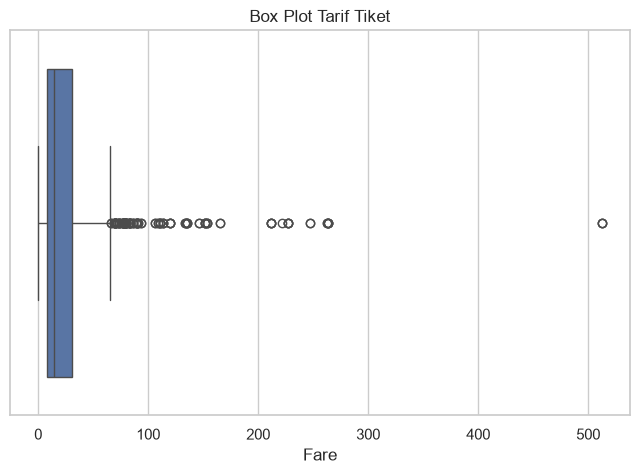

In [261]:
# Box plot tarif untuk melihat pencilan (outlier)
sns.boxplot(data=df, x="Fare")
plt.title("Box Plot Tarif Tiket")
plt.xlabel("Fare")
plt.show()

Tarif tiket tersebar secara tidak merata dan banyak sekali data pencilan, kemungkinan besar fitur ini harus distandardisasi

### 3.6 Ukuran keluarga

In [262]:
# Membuat fitur sementara untuk analisis jumlah anggota keluarga
family_eda = df["SibSp"] + df["Parch"] + 1
df["FamilySize"] = family_eda

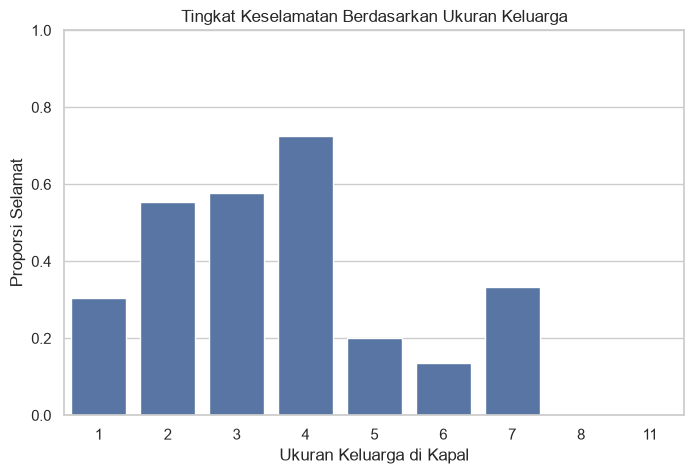

In [263]:
sns.barplot(data=df, x="FamilySize", y="Survived", errorbar=None)
plt.title("Tingkat Keselamatan Berdasarkan Ukuran Keluarga")
plt.xlabel("Ukuran Keluarga di Kapal")
plt.ylabel("Proporsi Selamat")
plt.ylim(0, 1)
plt.show()

Ukuran keluarga berukuran 4 memiliki tingkat keselamatan paling tinggi

### 3.7 Korelasi fitur numerik

In [264]:
# Korelasi hanya dihitung untuk kolom numerik
numeric_corr = df.select_dtypes(include=np.number).corr()
numeric_corr

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare,FamilySize
PassengerId,1.000000,-0.005007,-0.035144,0.036847,-0.057527,-0.001652,0.012658,-0.040143
Survived,-0.005007,1.000000,-0.338481,-0.077221,-0.035322,0.081629,0.257307,0.016639
Pclass,-0.035144,-0.338481,1.000000,-0.369226,0.083081,0.018443,-0.549500,0.065997
Age,0.036847,-0.077221,-0.369226,1.000000,-0.308247,-0.189119,0.096067,-0.301914
SibSp,-0.057527,-0.035322,0.083081,-0.308247,1.000000,0.414838,0.159651,0.890712
Parch,-0.001652,0.081629,0.018443,-0.189119,0.414838,1.000000,0.216225,0.783111
Fare,0.012658,0.257307,-0.549500,0.096067,0.159651,0.216225,1.000000,0.217138
FamilySize,-0.040143,0.016639,0.065997,-0.301914,0.890712,0.783111,0.217138,1.000000


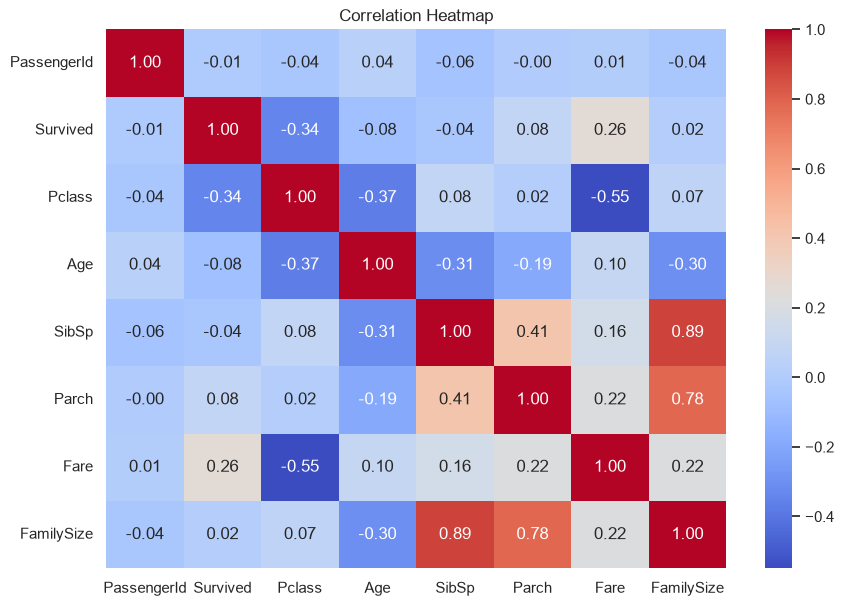

In [265]:
plt.figure(figsize=(10, 7))
sns.heatmap(numeric_corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

## 4. Pemeriksaan kualitas data

In [266]:
# Jumlah missing values setiap kolom
missing_count = df.isnull().sum().sort_values(ascending=False)
missing_count

Cabin          687
Age            177
Embarked         2
Survived         0
PassengerId      0
Sex              0
Name             0
Pclass           0
SibSp            0
Ticket           0
Parch            0
Fare             0
FamilySize       0
dtype: int64

In [267]:
# Persentase missing values
missing_percentage = (df.isnull().mean() * 100).sort_values(ascending=False)
missing_percentage

Cabin          77.104377
Age            19.865320
Embarked        0.224467
Survived        0.000000
PassengerId     0.000000
Sex             0.000000
Name            0.000000
Pclass          0.000000
SibSp           0.000000
Ticket          0.000000
Parch           0.000000
Fare            0.000000
FamilySize      0.000000
dtype: float64

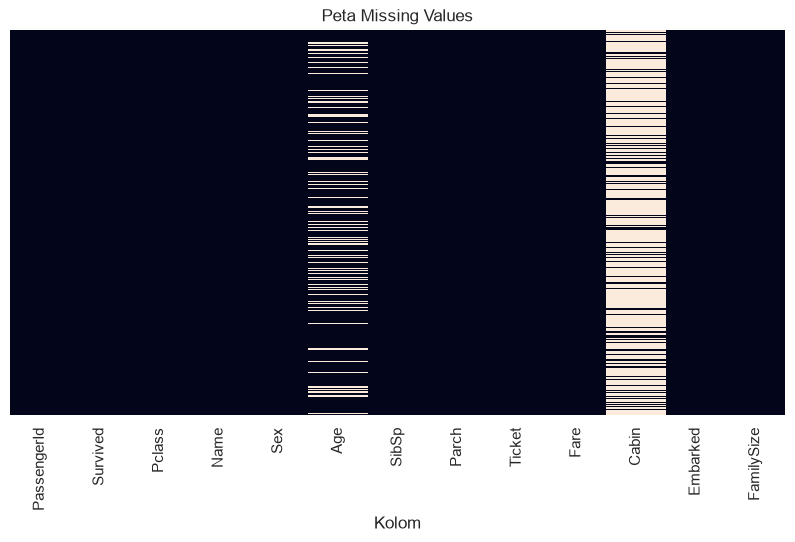

In [268]:
# Visualisasi missing values
plt.figure(figsize=(10, 5))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False)
plt.title("Peta Missing Values")
plt.xlabel("Kolom")
plt.show()

In [269]:
# Jumlah baris duplikat
df.duplicated().sum()

np.int64(0)

Seperti yang sudah diketahui diawal menggunakan fungsi describe, Cabin memiliki kolom kosong terbanyak dengan jumlah 687, diikuti oleh Age dengan jumlah 177 dan Embarked dengan jumlah 2. Diketahui juga tidak ada baris duplikat pada data

## 5. Data Preprocessing

### 5.1 Feature engineering

Menambah fitur baru yakni
- FamilySize: jumlah saudara/pasangan + orang tua/anak + si penumpang
- IsAlone: 1 jika sendiri, 0 selain itu

In [270]:
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
df["IsAlone"] = (df["FamilySize"] == 1).astype(int)

In [271]:
df[["SibSp", "Parch", "FamilySize"]].head()

,SibSp,Parch,FamilySize
0,1,0,2
1,1,0,2
2,0,0,1
3,1,0,2
4,0,0,1


### 5.2 Menentukan fitur dan target

Target yang ingin diprediksi adalah Survived.

Penghapusan kolom PassengerId, Name dan Ticket karena merupakan id/teks bebas dengan banyak variasi. Cabin juga dihilangkan karena proposi NaNnya sangat besar.

In [272]:
# Pisahkan target dan fitur
target = "Survived"

drop_columns = ["Survived", "PassengerId", "Name", "Ticket", "Cabin"]
X = df.drop(columns=[col for col in drop_columns if col in df.columns])
y = df[target]

print("Ukuran fitur:", X.shape)
print("Ukuran target:", y.shape)

Ukuran fitur: (891, 9)
Ukuran target: (891,)


In [273]:
# Pastikan target tidak memiliki missing values
y.isnull().sum()

np.int64(0)

### 5.3 Menentukan kolom numerik dan kategorikal

In [274]:
# Identifikasi kolom berdasarkan tipe data
numeric_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

print("Fitur numerik:", numeric_features)
print("Fitur kategorikal:", categorical_features)

Fitur numerik: ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'FamilySize', 'IsAlone']
Fitur kategorikal: ['Sex', 'Embarked']


C:\Users\NathanLampoenk2\AppData\Local\Temp\ipykernel_16200\3879180484.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


### 5.4 Menangani missing values

Penanganan:
- Fitur numerik: nilai kosong diisi dengan median
- Fitur kategorikal: nilai kosong diisi dengan modus

In [275]:
from sklearn.impute import SimpleImputer

numeric_imputer = SimpleImputer(strategy="median")
categorical_imputer = SimpleImputer(strategy="most_frequent")

In [276]:
# Terapkan imputasi pada seluruh fitur
X_num_imputed = numeric_imputer.fit_transform(X[numeric_features])
X_cat_imputed = categorical_imputer.fit_transform(X[categorical_features])

In [277]:
# Periksa apakah masih ada missing values setelah imputasi
print("Missing numerik:", np.isnan(X_num_imputed).sum())
print("Missing kategorikal:", pd.isna(X_cat_imputed).sum())

Missing numerik: 0
Missing kategorikal: 0


Missing values berhasil diisi dengan penanganan yang disebutkan di atas dan sudah tidak ada missing values lagi

### 5.5 Encoding fitur kategorikal

One-Hot Encoding utk Sex & Embarked, menghasilkan kolom biner untuk tiap kategori sehingga kategori tidak dianggap memiliki urutan tertentu.

In [278]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

In [279]:
X_cat_encoded = encoder.fit_transform(X_cat_imputed)

encoded_names = encoder.get_feature_names_out(categorical_features)
print("Kolom hasil encoding:", encoded_names)

Kolom hasil encoding: ['Sex_female' 'Sex_male' 'Embarked_C' 'Embarked_Q' 'Embarked_S']


### 5.6 Menggabungkan fitur numerik dan kategorikal

In [280]:
# Gabungkan fitur numerik (hasil imputasi) dan kategorikal (hasil encoding)
processed_feature_names = numeric_features + list(encoded_names)

X_processed = pd.DataFrame(
    np.hstack([X_num_imputed, X_cat_encoded]),
    columns=processed_feature_names,
    index=X.index
)

print("Ukuran fitur setelah encoding:", X_processed.shape)
X_processed.head()

Ukuran fitur setelah encoding: (891, 12)


,Pclass,Age,SibSp,Parch,Fare,FamilySize,IsAlone,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
0,3.0,22.0,1.0,0.0,7.2500,2.0,0.0,0.0,1.0,0.0,0.0,1.0
1,1.0,38.0,1.0,0.0,71.2833,2.0,0.0,1.0,0.0,1.0,0.0,0.0
2,3.0,26.0,0.0,0.0,7.9250,1.0,1.0,1.0,0.0,0.0,0.0,1.0
3,1.0,35.0,1.0,0.0,53.1000,2.0,0.0,1.0,0.0,0.0,0.0,1.0
4,3.0,35.0,0.0,0.0,8.0500,1.0,1.0,0.0,1.0,0.0,0.0,1.0


### 5.7 Membagi data training dan testing

In [281]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_processed,
    y,
    test_size=0.3,
    random_state=20,
    stratify=y
)

print("Data training:", X_train.shape)
print("Data testing :", X_test.shape)

Data training: (623, 12)
Data testing : (268, 12)


Dibagi dengan 70/30, 70% training / 30% testing

### 5.8 Scaling fitur numerik

StandardScaler digunakan agar fitur numerik memiliki rata rata sekitar 0 dan standar deviasi sekitar 1, agar skala fitur seimbang dan tidak ada yang mendominasi.

In [282]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

In [283]:
# Scaler hanya mempelajari rata-rata dan standar deviasi dari data training
X_train_processed_df = X_train.copy()
X_test_processed_df = X_test.copy()

X_train_processed_df[numeric_features] = scaler.fit_transform(X_train[numeric_features])
X_test_processed_df[numeric_features] = scaler.transform(X_test[numeric_features])

In [284]:
# Contoh pemeriksaan rata-rata dan standar deviasi hasil scaling
print("Rata-rata fitur train:", np.round(X_train_processed_df[numeric_features].mean().values, 2))
print("Standar deviasi train:", np.round(X_train_processed_df[numeric_features].std(ddof=0).values, 2))

Rata-rata fitur train: [ 0. -0. -0. -0.  0. -0. -0.]
Standar deviasi train: [1. 1. 1. 1. 1. 1. 1.]


### 5.9 Hasil akhir preprocessing

In [285]:
# Ubah ke array untuk dipakai model
X_train_processed = X_train_processed_df.values
X_test_processed = X_test_processed_df.values

print("Training setelah preprocessing:", X_train_processed.shape)
print("Testing setelah preprocessing :", X_test_processed.shape)

Training setelah preprocessing: (623, 12)
Testing setelah preprocessing : (268, 12)


In [286]:
X_train_processed_df.head()

,Pclass,Age,SibSp,Parch,Fare,FamilySize,IsAlone,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
638,0.83005,0.904049,-0.496762,5.851215,0.113996,2.556004,-1.201306,1.0,0.0,0.0,0.0,1.0
521,0.83005,-0.572950,-0.496762,-0.479641,-0.475279,-0.581093,0.832427,0.0,1.0,0.0,0.0,1.0
381,0.83005,-2.205423,-0.496762,2.052701,-0.329851,0.673746,-1.201306,1.0,0.0,1.0,0.0,0.0
104,0.83005,0.593102,1.318385,-0.479641,-0.474737,0.673746,-1.201306,0.0,1.0,0.0,0.0,1.0
19,0.83005,-0.106529,-0.496762,-0.479641,-0.487712,-0.581093,0.832427,1.0,0.0,1.0,0.0,0.0


In [287]:
# Pastikan data hasil preprocessing tidak mengandung missing values
print("Missing train:", X_train_processed_df.isnull().sum().sum())
print("Missing test :", X_test_processed_df.isnull().sum().sum())

Missing train: 0
Missing test : 0


## 6. Ringkasan hasil dan kesimpulan

### Ringkasan EDA
1. Target Survived terdiri dari dua kelas: tidak selamat (0) dan selamat (1).
2. Jenis kelamin menunjukkan hubungan yang kuat dengan keselamatan dengan perempuan memiliki tingkat keselamatan lebih tinggi.
3. Kelas tiket (Pclass) juga berkaitan dengan keselamatan, penumpang kelas 1 cenderung memiliki tingkat keselamatan lebih tinggi daripada kelas 3.
4. Usia dan tarif tiket memiliki distribusi yang tidak simetris.
5. Ukuran keluarga (FamilySize) dapat memberikan informasi tambahan untuk analisis keselamatan.

### Ringkasan preprocessing
1. Dibuat fitur baru FamilySize dan IsAlone.
2. Kolom dengan isian teks bebas / id (PassengerId, Name, Ticket) dan Cabin yang memiliki terlalu banyak nilai NaN dihilangkan, lalu Survived dipisahkan sebagai target.
3. Missing values numerik diisi median, sedangkan kategorikal diisi modus.
4. Fitur kategorikal diubah menggunakan One-Hot Encoding.
5. Data dibagi menjadi training dan testing.
6. Fitur numerik distandardisasi menggunakan StandardScaler (dipelajari dari data training saja).

X_train_processed dan X_test_processed sudah berbentuk numerik dan siap digunakan untuk melatih model klasifikasi dengan y_train dan y_test merupakan label targetnya.

In [288]:
print("X_train_processed:", X_train_processed.shape)
print("X_test_processed :", X_test_processed.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train_processed: (623, 12)
X_test_processed : (268, 12)
y_train: (623,)
y_test : (268,)


## 7. Modeling

In [289]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()
model.fit(X_train_processed, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [290]:
y_pred = model.predict(X_test_processed)
y_pred

array([0, 1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0,
       0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0,
       0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0,
       0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 1, 0, 0,
       0, 0, 1, 1, 1, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 1, 0, 1,
       1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0,
       1, 1, 0, 1, 0, 0, 1, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1,
       1, 0, 1, 1, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1, 1, 0, 1,
       1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0,
       1, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1,
       0, 1, 0, 1])

In [291]:
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score, recall_score, precision_score

print(confusion_matrix(y_test, y_pred))
print(f"Akurasi\t\t: ", accuracy_score(y_test, y_pred))
print(f"Recall\t\t: ", recall_score(y_test, y_pred))
print(f"Precision\t: ", precision_score(y_test, y_pred))
print(f"F1 Score\t: ", f1_score(y_test, y_pred))

[[147  18]
 [ 27  76]]
Akurasi		:  0.832089552238806
Recall		:  0.7378640776699029
Precision	:  0.8085106382978723
F1 Score	:  0.7715736040609137


Hasilnya (confusion matrix berformat `[[TN, FP], [FN, TP]]`, dengan kelas positif = 1 atau selamat):

- True Negative (TN) -> 141 (sebanyak 141 penumpang yang tidak selamat diprediksi tidak selamat dengan benar)
- False Positive (FP) -> 24 (sebanyak 24 penumpang yang tidak selamat salah diprediksi selamat)
- False Negative (FN) -> 29 (sebanyak 29 penumpang yang selamat salah diprediksi tidak selamat)
- True Positive (TP) -> 74 (sebanyak 74 penumpang yang selamat diprediksi selamat dengan benar)